# 01 · Exploración del ranking SCVS 2025

**Componente B · Sprint 2 (ETL)** · Fase CRISP-DM: *comprensión de los datos* · Capa: **bronce** (solo lectura)

Objetivo: conocer el archivo crudo antes de limpiarlo. Este notebook **no modifica ni guarda datos**; sus hallazgos definen las reglas de calidad del notebook 02.

| Entrada | Origen |
| --- | --- |
| `datos/crudo/2025/ranking_2025.xlsx` | Ranking empresarial SCVS 2025, corte 22-oct-2026 |
| `datos/crudo/MANIFEST.csv` | Procedencia y hash de cada descarga |

In [1]:
from pathlib import Path

ETL = Path.cwd().resolve()
if ETL.name == "notebooks":
    ETL = ETL.parent
DATOS = ETL / "datos"
CRUDO = DATOS / "crudo"      # bronce: datos tal como llegan, sin modificar
SCVS = CRUDO / "2025"        # descargas oficiales de la SCVS
WEB = CRUDO / "web"          # páginas capturadas de las webs oficiales
PLATA = DATOS / "plata"      # datos limpios y validados
ORO = DATOS / "oro"          # datos listos para publicar
for carpeta in (WEB, PLATA, ORO):
    carpeta.mkdir(parents=True, exist_ok=True)

In [2]:
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Procedencia: el archivo es el mismo que registra el MANIFEST

In [3]:
def sha256(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

manifest = pd.read_csv(CRUDO / "MANIFEST.csv", dtype=str)
manifest["sha256_actual"] = [sha256(CRUDO / a) for a in manifest["archivo"]]
manifest["coincide"] = manifest["sha256"] == manifest["sha256_actual"]
manifest[["archivo", "fecha_descarga", "descargado_por", "coincide"]]

,archivo,fecha_descarga,descargado_por,coincide
0,2025/ranking_2025.xlsx,2026-11-09,Pereira,True
1,2025/bi_ciiu.csv,2026-11-09,Pereira,True
2,2025/bi_compania.csv,2026-11-03,Muzo,True
3,2025/bi_segmento.csv,2026-11-03,Muzo,True


In [4]:
assert manifest["coincide"].all(), "Algún archivo crudo cambió: no coincide con su hash"

## 2. Estructura del archivo

El encabezado ocupa dos filas: la primera trae la fecha de corte y la segunda los nombres. Las cuatro primeras columnas son dos pares *Posición/Año*: el ranking 2025 y el anterior (2024).

In [5]:
ARCHIVO = SCVS / "ranking_2025.xlsx"
fila_titulo = pd.read_excel(ARCHIVO, engine="calamine", header=None, nrows=1).iloc[0, 0]
crudo = pd.read_excel(ARCHIVO, engine="calamine", header=1)
print(fila_titulo)
print(crudo.shape)
list(crudo.columns)

Fecha de corte - Thu Oct 22 00:01:13 ECT 2026
(154813, 22)


['Posición',
 'Año',
 'Posición.1',
 'Año.1',
 'Expediente',
 'Nombre',
 'Tipo Compañia',
 'Actividad económica',
 'Región',
 'Provincia',
 'Ciudad',
 'Tamaño',
 'Sector',
 'Cant. Empleados',
 'Activio\n2025',
 'Patrimonio\n2025',
 'Ingreso por ventas\n2025',
 'Utilidad antes del impuesto\n2025',
 'Utilidad del ejercicio\n2025',
 'Utilidad neta\n2025',
 'IR causado\n2025',
 'Ingreso Total\n2025']

In [6]:
NOMBRES = [
    "posicion_2025", "anio_2025", "posicion_2024", "anio_2024", "expediente", "nombre",
    "tipo_compania", "actividad", "region", "provincia", "ciudad", "tamano_scvs", "sector_scvs",
    "empleados", "activo", "patrimonio", "ventas", "utilidad_antes_impuesto",
    "utilidad_ejercicio", "utilidad_neta", "ir_causado", "ingreso_total",
]
d = crudo.copy()
d.columns = NOMBRES
for c in ["nombre", "tipo_compania", "actividad", "region", "provincia", "ciudad", "sector_scvs"]:
    d[c] = d[c].str.strip()
d.head(3)

,posicion_2025,anio_2025,posicion_2024,anio_2024,expediente,nombre,tipo_compania,actividad,region,provincia,ciudad,tamano_scvs,sector_scvs,empleados,activo,patrimonio,ventas,utilidad_antes_impuesto,utilidad_ejercicio,utilidad_neta,ir_causado,ingreso_total
0,0,0,14373,2024,32814,TECMASUR ELECTRONICA INTEGRAL CIA. LTDA.,RESPONSABILIDAD LIMITADA,C3314.03 - SERVICIOS DE REPARACIÓN Y MANTENIMI...,SIERRA,AZUAY,CUENCA,NaN,SOCIETARIO,5,"844,957.69","100,686.33","603,054.16","35,562.66","41,838.42","15,371.90","20,190.76","603,054.16"
1,0,0,0,0,93041,SISD CIA. LTDA. SEGURIDAD INTERNACIONAL & SIST...,RESPONSABILIDAD LIMITADA,N8010.03 - SERVICIOS DE GUARDIAS DE SEGURIDAD.,SIERRA,PICHINCHA,QUITO,NaN,SOCIETARIO,4,"10,800.00","10,800.00",0.00,0.00,0.00,0.00,0.00,0.00
2,0,0,19135,2024,176037,GRIALNOVA S.A.,ANÓNIMA,G4669.21 - VENTA AL POR MAYOR DE MATERIALES PL...,COSTA,GUAYAS,GUAYAQUIL,NaN,SOCIETARIO,5,"557,225.37","221,202.04","816,401.24","47,360.29","55,717.98","35,957.37","11,402.92","863,453.38"


## 3. Completitud

In [7]:
nulos = d.isna().sum()
nulos[nulos > 0]

tamano_scvs    154813
dtype: int64

> `tamano_scvs` viene vacía en **todas** las filas: el tamaño oficial no se puede usar y hay que derivarlo (notebook 02).

## 4. Duplicados

In [8]:
repetidos = d[d["expediente"].duplicated(keep=False)]
print("expedientes repetidos:", d["expediente"].duplicated().sum())
print("filas idénticas:", d.duplicated().sum())

distintos = repetidos.groupby("expediente").filter(lambda g: len(g.drop_duplicates()) > 1)
cols_que_cambian = (
    distintos.groupby("expediente").nunique().gt(1).sum().loc[lambda s: s > 0]
)
print("expedientes repetidos con filas distintas:", distintos["expediente"].nunique())
cols_que_cambian

expedientes repetidos: 126


filas idénticas: 116


expedientes repetidos con filas distintas: 10


actividad    10
dtype: int64

## 5. Registros incompletos o sin actividad

In [9]:
sin_actividad = (d["ventas"] == 0) & (d["activo"] == 0) & (d["ingreso_total"] == 0)
pd.Series({
    "año 2025 = 0": int((d["anio_2025"] == 0).sum()),
    "nuevas en el ranking (sin posición 2024)": int((d["anio_2024"] == 0).sum()),
    "ventas = 0": int((d["ventas"] == 0).sum()),
    "sin actividad (ventas, activo e ingreso en 0)": int(sin_actividad.sum()),
})

año 2025 = 0                                        30
nuevas en el ranking (sin posición 2024)         22551
ventas = 0                                       58955
sin actividad (ventas, activo e ingreso en 0)     4354
dtype: int64

## 6. Variables categóricas

In [10]:
for c in ["tipo_compania", "region", "sector_scvs"]:
    display(d[c].value_counts().to_frame())

,count
tipo_compania,
SOCIEDAD POR ACCIONES SIMPLIFICADA,64071
ANÓNIMA,62772
RESPONSABILIDAD LIMITADA,27241
SUCURSAL EXTRANJERA,689
ECONOMÍA MIXTA,22
ANÓNIMA EN PREDIOS RÚSTICOS,10
ANÓNIMA MULTINACIONAL ANDINA,4
ASOCIACIÓN O CONSORCIO,3
COMANDITA POR ACCIONES,1


,count
region,
COSTA,74658
SIERRA,73398
ORIENTE,5623
GALAPAGOS,1134


,count
sector_scvs,
SOCIETARIO,154391
MERCADO DE VALORES,422


CIIU con formato inválido: 0


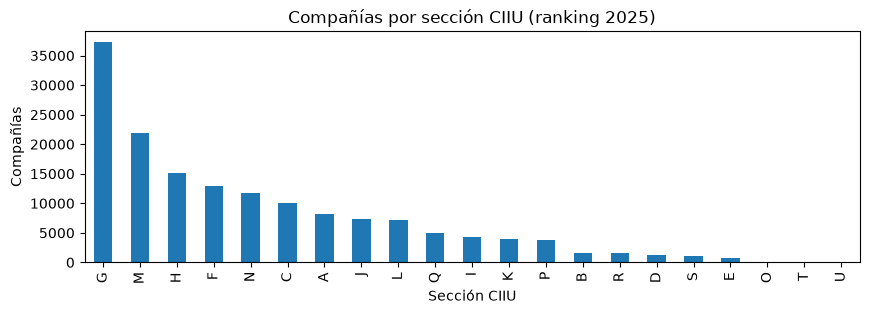

In [11]:
d["ciiu"] = d["actividad"].str.split(" - ", n=1).str[0].str.strip()
print("CIIU con formato inválido:", (~d["ciiu"].str.match(r"^[A-U]\d{4}")).sum())
seccion = d["ciiu"].str[0].value_counts()
ax = seccion.plot.bar(figsize=(10, 3), title="Compañías por sección CIIU (ranking 2025)")
ax.set_xlabel("Sección CIIU"); ax.set_ylabel("Compañías")
plt.show()

## 7. Cifras: ceros, negativos y extremos

In [12]:
CIFRAS = ["empleados", "activo", "patrimonio", "ventas", "utilidad_neta", "ingreso_total"]
pd.DataFrame({
    "ceros": [(d[c] == 0).sum() for c in CIFRAS],
    "negativos": [(d[c] < 0).sum() for c in CIFRAS],
    "mediana": [d[c].median() for c in CIFRAS],
    "máximo": [d[c].max() for c in CIFRAS],
}, index=CIFRAS)

,ceros,negativos,mediana,máximo
empleados,0,0,4.00,"1,722,151,868.00"
activo,4724,0,"20,337.57","2,788,469,579.72"
patrimonio,4122,17491,"3,228.09","1,946,118,211.59"
ventas,58955,0,"9,000.00","2,690,137,857.78"
utilidad_neta,53546,30868,0.00,"515,905,137.29"
ingreso_total,56841,0,"10,268.44","2,690,137,857.78"


Lectura:

- **Patrimonio negativo** y **utilidad negativa** son situaciones reales (quiebra técnica, pérdidas): se conservan.
- El **máximo de empleados** es imposible (más de mil millones): error de registro.

In [13]:
d[d["empleados"] > 100_000][["expediente", "nombre", "empleados", "ventas"]]

,expediente,nombre,empleados,ventas
49463,105507,TELEDOM S.A.,928267662,"87,929.44"
108481,390015,EMPRESA DE TRANSPORTE PESADO ALFATRANSAGUILTRA...,1722151868,0.00


## 8. Coherencia contable

In [14]:
pd.Series({
    "ventas > ingreso total": int((d["ventas"] > d["ingreso_total"] + 1).sum()),
    "utilidad neta positiva > ingreso total": int(((d["utilidad_neta"] > d["ingreso_total"]) & (d["utilidad_neta"] > 0)).sum()),
})

ventas > ingreso total                      0
utilidad neta positiva > ingreso total    203
dtype: int64

## 9. El dato de empleados (caso Tiendas Tuti)

Se compara cuánto vende cada empresa por empleado con lo típico de su división CIIU.

In [15]:
d["division"] = d["ciiu"].str[:3]
d["ventas_por_empleado"] = d["ventas"] / d["empleados"]
mediana_div = d[d["empleados"] >= 10].groupby("division")["ventas_por_empleado"].median()
d["veces_mediana_division"] = d["ventas_por_empleado"] / d["division"].map(mediana_div)

d.nlargest(15, "ventas")[["nombre", "division", "empleados", "ventas", "ventas_por_empleado", "veces_mediana_division"]]

,nombre,division,empleados,ventas,ventas_por_empleado,veces_mediana_division
30,CORPORACION FAVORITA C.A.,G47,12033,"2,690,137,857.78","223,563.36",2.20
33,AURELIAN ECUADOR S.A,B07,1997,"1,741,956,698.60","872,286.78",24.31
31,ECUACORRIENTE S.A.,B07,1491,"1,664,822,958.33","1,116,581.46",31.11
32,INDUSTRIAL PESQUERA SANTA PRISCILA S.A.,A03,17315,"1,648,896,993.00","95,229.40",0.90
38,CORPORACION EL ROSADO S.A.,G47,6,"1,641,394,550.59","273,565,758.43","2,686.17"
152,PRIMAX COMERCIAL DEL ECUADOR SOCIEDAD ANONIMA,G46,136,"1,397,067,244.41","10,272,553.27",99.13
76,DINADEC S.A.,G46,968,"1,138,676,300.75","1,176,318.49",11.35
43,PROCESADORA NACIONAL DE ALIMENTOS C.A. PRONACA,C10,7445,"1,133,424,282.57","152,239.66",1.90
36,CONSORCIO ECUATORIANO DE TELECOMUNICACIONES S....,J61,3302,"1,030,666,288.95","312,133.95",9.94
79,TIENDAS TUTI TTDE S.A.,G47,8,"1,008,144,377.94","126,018,047.24","1,237.38"


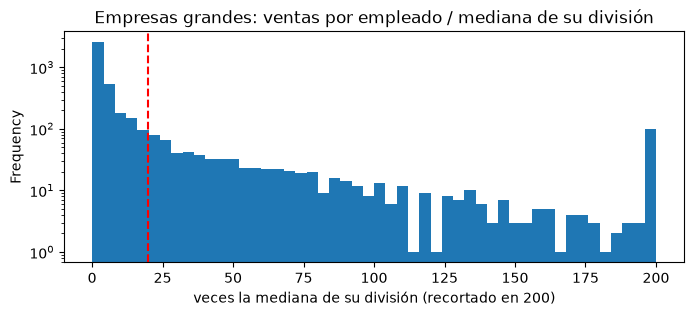

In [16]:
ax = d.loc[d["ventas"] > 5_000_000, "veces_mediana_division"].clip(upper=200).plot.hist(
    bins=50, log=True, figsize=(8, 3), title="Empresas grandes: ventas por empleado / mediana de su división")
ax.axvline(20, color="red", linestyle="--")
ax.set_xlabel("veces la mediana de su división (recortado en 200)")
plt.show()

## Hallazgos que pasan al notebook 02

| # | Hallazgo | Regla en plata |
| --- | --- | --- |
| 1 | `Tamaño` vacía | Derivar por ventas (COPCI) → `tamano_derivado` |
| 2 | Expedientes repetidos (idénticos y con diferencias) | Quitar idénticos; de los distintos, conservar el de mejor posición 2025 y registrarlo |
| 3 | Año 2025 = 0 | Marcar `anio_cero` y excluir del universo |
| 4 | Sin actividad (todo en cero) | Marcar `sin_actividad` |
| 5 | Empleados imposibles (> 100.000) | Marcar `empleados_imposible` |
| 6 | Ventas por empleado muy por encima de su división | `alerta_empleados` con su causa |
| 7 | Utilidad neta mayor que el ingreso total | Marcar `revisar_utilidad` |
| 8 | CIIU y descripción en una columna | Separar código, sección y división |